# Project - Subject-Independent Recognition of Gym Exercises from Wearable Sensors

| **Student Name** | **Hemanth Kumar Reddyvari** |
|---|---|
| Student ID | a3185100 |
| Course Name | Programming for Artificial Intelligence and Machine Learning 2 |

In this notebook I am doing the main pipeline and experiments of the project on the RecGym dataset: 4 second windows of wrist, leg and pocket sensor signal, 12 classes (11 exercises plus rest). Four models - Majority baseline, Keras feature network, 1D CNN and LSTM (PyTorch).

Every model is tested two ways: a random 80/20 split, and leave-one-subject-out (LOSO) on 10 people. The protocol gap is random split macro F1 minus LOSO mean macro F1. Also per-class F1, per-person F1 and confusion matrix for each run, plus the sensor position experiment (wrist vs leg vs pocket).

Before running, change runtime to GPU: Runtime -> Change runtime type -> T4 GPU. Then run the sections in order (you need `kaggle.json` for the data download). The Results and Figures sections only read saved files, so they can be run on their own after Imports and settings.

The experiments added after the milestone are in `AIML Workout Extensions.ipynb`.


## 1. Setup
Download RecGym from Kaggle (needs `kaggle.json`).
With `var_usedrive_bool = True` the window cache and results are kept on Drive and survive a disconnect.
With `False` everything stays in `/content`, is lost when the session ends, and is downloaded as a zip at the end.

In [ ]:
from google.colab import drive, files

var_usedrive_bool = False  # True = save to Google Drive

if var_usedrive_bool:
    drive.mount('/content/drive')

files.upload()  # upload kaggle.json

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!pip install -q kaggle
!kaggle datasets download -d zhaxidelebsz/10-gym-exercises-with-615-abstracted-features -p /content
!unzip -q -o /content/10-gym-exercises-with-615-abstracted-features.zip -d /content/recgym
!ls -lh /content/recgym

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/zhaxidelebsz/10-gym-exercises-with-615-abstracted-features
License(s): MIT
100% 111M/111M [00:00<00:00, 146MB/s] 

total 454M
-rw-r--r-- 1 root root 454M Mar  6  2025 RecGym.csv


## 2. Imports and settings

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
# TensorFlow is imported inside train_keras, see Models

from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

var_device_obj = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", var_device_obj)

# paths: Drive if switched on in Setup, otherwise session storage
if var_usedrive_bool:
    assert os.path.ismount('/content/drive'), "Drive not mounted, run Setup first"
    var_basedir_txt = "/content/drive/MyDrive/paiml2"
else:
    var_basedir_txt = "/content/paiml2"
print("Saving to:", var_basedir_txt)

var_csvpath_txt = "/content/recgym/RecGym.csv"
var_cachedir_txt = f"{var_basedir_txt}/cache"
var_resultsdir_txt = f"{var_basedir_txt}/results_final"
var_figuresdir_txt = f"{var_basedir_txt}/figures_final"
var_logpath_txt = f"{var_resultsdir_txt}/results_log.csv"

for var_folder_txt in [var_cachedir_txt, var_resultsdir_txt, var_figuresdir_txt]:
    os.makedirs(var_folder_txt, exist_ok=True)

# settings, same for every model
var_seed_int = 42
var_window_int = 80       # 4 s at 20 Hz
var_stride_int = 40       # 2 s overlap
var_purity_float = 0.9    # drop windows that mix two activities
var_channels_list = ['A_x', 'A_y', 'A_z', 'G_x', 'G_y', 'G_z', 'C_1']
var_epochs_int = 40
var_batch_int = 256
var_lr_float = 1e-3

Device: cuda
Saving to: /content/paiml2


## 3. Data
Windows are built inside each subject and session, so no window mixes two people.
CNN and LSTM get per-window standardised signal. The Keras model gets summary features from the raw windows.

In [ ]:
def build_windows(var_position_txt):
    # load from cache if built before
    var_cachepath_txt = f"{var_cachedir_txt}/{var_position_txt}_w{var_window_int}_s{var_stride_int}.npz"
    if os.path.exists(var_cachepath_txt):
        print("Loading cached windows:", var_cachepath_txt)
        var_cache_npz = np.load(var_cachepath_txt, allow_pickle=True)
        return (var_cache_npz['X'], var_cache_npz['y'],
                var_cache_npz['subjects'], list(var_cache_npz['labels']))

    print(f"Building windows for {var_position_txt} (slow, runs once)")
    assert os.path.exists(var_csvpath_txt), "RecGym.csv missing, run Setup"
    var_columns_list = ['Subject', 'Session', 'Position', 'Workout'] + var_channels_list
    var_data_df = pd.read_csv(var_csvpath_txt, usecols=var_columns_list)  # only needed columns, saves RAM
    var_data_df = var_data_df[var_data_df['Position'] == var_position_txt]

    var_labels_list = sorted(var_data_df['Workout'].unique())
    var_labelmap_dict = {var_label_txt: i for i, var_label_txt in enumerate(var_labels_list)}

    var_x_list, var_y_list, var_subjects_list = [], [], []
    for (var_subject_int, var_session_int), var_group_df in var_data_df.groupby(['Subject', 'Session'], sort=False):
        var_signal_arr = var_group_df[var_channels_list].to_numpy(dtype=np.float32)
        var_label_arr = var_group_df['Workout'].map(var_labelmap_dict).to_numpy()

        for var_start_int in range(0, len(var_signal_arr) - var_window_int + 1, var_stride_int):
            var_window_labels_arr = var_label_arr[var_start_int:var_start_int + var_window_int]
            var_counts_arr = np.bincount(var_window_labels_arr, minlength=len(var_labels_list))
            var_main_int = var_counts_arr.argmax()
            if var_counts_arr[var_main_int] < var_purity_float * var_window_int:
                continue  # mixed window
            var_x_list.append(var_signal_arr[var_start_int:var_start_int + var_window_int])
            var_y_list.append(var_main_int)
            var_subjects_list.append(var_subject_int)

    var_x_arr = np.stack(var_x_list)
    var_y_arr = np.array(var_y_list)
    var_subjects_arr = np.array(var_subjects_list)
    np.savez_compressed(var_cachepath_txt, X=var_x_arr, y=var_y_arr, subjects=var_subjects_arr,
                        labels=np.array(var_labels_list, dtype=object))
    print("Cached to", var_cachepath_txt)
    return var_x_arr, var_y_arr, var_subjects_arr, var_labels_list


def standardise_windows(var_x_arr):
    # each channel to mean 0, std 1 within its own window
    var_mean_arr = var_x_arr.mean(axis=1, keepdims=True)
    var_std_arr = var_x_arr.std(axis=1, keepdims=True) + 1e-6
    return ((var_x_arr - var_mean_arr) / var_std_arr).astype(np.float32)


def extract_features(var_x_arr):
    # 7 stats x 7 channels = 49 features, from RAW windows
    var_features_list = [
        var_x_arr.mean(axis=1),
        var_x_arr.std(axis=1),
        var_x_arr.min(axis=1),
        var_x_arr.max(axis=1),
        np.percentile(var_x_arr, 25, axis=1),
        np.percentile(var_x_arr, 75, axis=1),
        np.abs(np.diff(var_x_arr, axis=1)).mean(axis=1),  # mean absolute change
    ]
    return np.concatenate(var_features_list, axis=1).astype(np.float32)


def load_position(var_position_txt):
    var_x_arr, var_y_arr, var_subjects_arr, var_labels_list = build_windows(var_position_txt)
    print(f"{var_position_txt}: {var_x_arr.shape[0]:,} windows, {len(var_labels_list)} classes")
    return {
        "position": var_position_txt,
        "x_std": standardise_windows(var_x_arr),   # CNN, LSTM
        "features": extract_features(var_x_arr),   # Majority, Keras
        "y": var_y_arr,
        "subjects": var_subjects_arr,
        "labels": var_labels_list,
        "n_cls": len(var_labels_list),
        "n_ch": var_x_arr.shape[2],
    }

## 4. Models
Majority baseline, Keras dense net on features, 1D CNN and LSTM (PyTorch).
All use inverse-frequency class weights from the training fold, 40 epochs, Adam, lr 0.001, batch 256.

In [ ]:
def class_weights(var_y_arr, var_ncls_int):
    # inverse frequency, training fold only
    var_counts_arr = np.bincount(var_y_arr, minlength=var_ncls_int).astype(np.float32)
    return var_counts_arr.sum() / (var_ncls_int * np.maximum(var_counts_arr, 1))


class CNN(nn.Module):
    def __init__(self, var_nch_int, var_ncls_int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(var_nch_int, 64, 7, padding=3), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 256, 3, padding=1), nn.BatchNorm1d(256), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.drop = nn.Dropout(0.3)
        self.head = nn.Linear(256, var_ncls_int)

    def forward(self, var_x_tensor):
        var_x_tensor = var_x_tensor.transpose(1, 2)  # Conv1d wants (batch, channels, time)
        var_x_tensor = self.net(var_x_tensor).squeeze(-1)
        return self.head(self.drop(var_x_tensor))


class LSTMNet(nn.Module):
    def __init__(self, var_nch_int, var_ncls_int, var_hidden_int=128):
        super().__init__()
        self.lstm = nn.LSTM(var_nch_int, var_hidden_int, num_layers=2, batch_first=True, dropout=0.3)
        self.drop = nn.Dropout(0.3)
        self.head = nn.Linear(var_hidden_int, var_ncls_int)

    def forward(self, var_x_tensor):
        var_out_tensor, _ = self.lstm(var_x_tensor)
        var_out_tensor = var_out_tensor.mean(dim=1)  # average hidden states over time
        return self.head(self.drop(var_out_tensor))


def train_torch(var_modelclass, var_data_dict, var_train_arr, var_test_arr):
    torch.manual_seed(var_seed_int)
    var_x_arr = var_data_dict['x_std']
    var_y_arr = var_data_dict['y']

    var_weights_tensor = torch.tensor(class_weights(var_y_arr[var_train_arr], var_data_dict['n_cls'])).to(var_device_obj)
    var_dataset_obj = torch.utils.data.TensorDataset(torch.tensor(var_x_arr[var_train_arr]),
                                                     torch.tensor(var_y_arr[var_train_arr]))
    var_loader_obj = torch.utils.data.DataLoader(var_dataset_obj, batch_size=var_batch_int, shuffle=True)

    var_model_obj = var_modelclass(var_data_dict['n_ch'], var_data_dict['n_cls']).to(var_device_obj)
    var_optimizer_obj = torch.optim.Adam(var_model_obj.parameters(), lr=var_lr_float)
    var_scheduler_obj = torch.optim.lr_scheduler.CosineAnnealingLR(var_optimizer_obj, T_max=var_epochs_int)
    var_lossfn_obj = nn.CrossEntropyLoss(weight=var_weights_tensor)

    for var_epoch_int in range(var_epochs_int):
        var_model_obj.train()
        for var_xb_tensor, var_yb_tensor in var_loader_obj:
            var_xb_tensor, var_yb_tensor = var_xb_tensor.to(var_device_obj), var_yb_tensor.to(var_device_obj)
            var_optimizer_obj.zero_grad()
            var_lossfn_obj(var_model_obj(var_xb_tensor), var_yb_tensor).backward()
            if var_modelclass is LSTMNet:
                nn.utils.clip_grad_norm_(var_model_obj.parameters(), 1.0)  # keeps LSTM stable
            var_optimizer_obj.step()
        var_scheduler_obj.step()

    # predict in batches
    var_model_obj.eval()
    var_xtest_tensor = torch.tensor(var_x_arr[var_test_arr])
    var_preds_list = []
    with torch.no_grad():
        for i in range(0, len(var_xtest_tensor), var_batch_int):
            var_batch_tensor = var_xtest_tensor[i:i + var_batch_int].to(var_device_obj)
            var_preds_list.append(var_model_obj(var_batch_tensor).argmax(1).cpu())
    return torch.cat(var_preds_list).numpy()


def train_cnn(var_data_dict, var_train_arr, var_test_arr):
    return train_torch(CNN, var_data_dict, var_train_arr, var_test_arr)


def train_lstm(var_data_dict, var_train_arr, var_test_arr):
    return train_torch(LSTMNet, var_data_dict, var_train_arr, var_test_arr)


def train_keras(var_data_dict, var_train_arr, var_test_arr):
    # import TF only after torch has used the GPU, else their cuDNN versions clash and Colab crashes
    import tensorflow as tf
    for var_gpu_obj in tf.config.list_physical_devices('GPU'):
        try:
            tf.config.experimental.set_memory_growth(var_gpu_obj, True)  # leave GPU memory for torch
        except RuntimeError:
            pass  # already set on an earlier call

    tf.keras.backend.clear_session()
    tf.random.set_seed(var_seed_int)
    var_f_arr = var_data_dict['features']
    var_y_arr = var_data_dict['y']

    var_scaler_obj = StandardScaler().fit(var_f_arr[var_train_arr])  # training fold only
    var_weights_arr = class_weights(var_y_arr[var_train_arr], var_data_dict['n_cls'])

    var_model_obj = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(var_f_arr.shape[1],)),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(var_data_dict['n_cls'], activation='softmax'),
    ])
    var_model_obj.compile(optimizer=tf.keras.optimizers.Adam(var_lr_float),
                          loss='sparse_categorical_crossentropy')
    var_model_obj.fit(var_scaler_obj.transform(var_f_arr[var_train_arr]), var_y_arr[var_train_arr],
                      epochs=var_epochs_int, batch_size=var_batch_int, verbose=0,
                      class_weight={i: float(w) for i, w in enumerate(var_weights_arr)})
    var_probs_arr = var_model_obj.predict(var_scaler_obj.transform(var_f_arr[var_test_arr]),
                                          batch_size=1024, verbose=0)
    return var_probs_arr.argmax(axis=1)


def train_majority(var_data_dict, var_train_arr, var_test_arr):
    # always predicts the most common training class (Null)
    var_model_obj = DummyClassifier(strategy="most_frequent")
    var_model_obj.fit(var_data_dict['features'][var_train_arr], var_data_dict['y'][var_train_arr])
    return var_model_obj.predict(var_data_dict['features'][var_test_arr])


var_models_dict = {
    "Majority": train_majority,
    "Keras-Features": train_keras,
    "CNN": train_cnn,
    "LSTM": train_lstm,
}

## 5. Evaluation
Runs one model under both protocols, prints the scores, saves per-class, per-subject and confusion matrix results, and appends one row to the results log.
Each run is logged as soon as it finishes, so a Colab disconnect only loses the run in progress.

In [ ]:
def run_protocols(var_data_dict, var_modelname_txt):
    var_position_txt = var_data_dict['position']
    var_y_arr = var_data_dict['y']
    var_subjects_arr = var_data_dict['subjects']
    var_ncls_int = var_data_dict['n_cls']
    var_train_fn = var_models_dict[var_modelname_txt]
    print(f"\n{'=' * 60}\n{var_position_txt} / {var_modelname_txt}\n{'=' * 60}")

    # protocol A: random 80/20 split, same people in train and test
    var_perm_arr = np.random.default_rng(var_seed_int).permutation(len(var_y_arr))
    var_cut_int = int(0.8 * len(var_y_arr))
    var_rtest_arr = var_perm_arr[var_cut_int:]
    var_rpred_arr = var_train_fn(var_data_dict, var_perm_arr[:var_cut_int], var_rtest_arr)
    var_rtrue_arr = var_y_arr[var_rtest_arr]

    var_random_acc_float = accuracy_score(var_rtrue_arr, var_rpred_arr)
    var_random_f1_float = f1_score(var_rtrue_arr, var_rpred_arr, average='macro', zero_division=0)
    var_random_pc_arr = f1_score(var_rtrue_arr, var_rpred_arr, average=None,
                                 labels=range(var_ncls_int), zero_division=0)
    print(f"  random split   acc {var_random_acc_float:.3f}  macroF1 {var_random_f1_float:.3f}")

    # protocol B: leave one subject out, 10 folds
    var_subject_list = sorted(np.unique(var_subjects_arr))
    var_acc_list, var_f1_list, var_pc_list = [], [], []
    var_loso_true_list, var_loso_pred_list = [], []

    for var_subject_int in var_subject_list:
        var_train_arr = np.where(var_subjects_arr != var_subject_int)[0]
        var_test_arr = np.where(var_subjects_arr == var_subject_int)[0]
        var_pred_arr = var_train_fn(var_data_dict, var_train_arr, var_test_arr)
        var_true_arr = var_y_arr[var_test_arr]

        var_acc_list.append(accuracy_score(var_true_arr, var_pred_arr))
        var_f1_list.append(f1_score(var_true_arr, var_pred_arr, average='macro', zero_division=0))
        var_pc_list.append(f1_score(var_true_arr, var_pred_arr, average=None,
                                    labels=range(var_ncls_int), zero_division=0))
        var_loso_true_list.append(var_true_arr)
        var_loso_pred_list.append(var_pred_arr)
        print(f"  subject {var_subject_int:>2}  n={len(var_test_arr):>5}  "
              f"acc {var_acc_list[-1]:.3f}  macroF1 {var_f1_list[-1]:.3f}")

    var_loso_acc_arr = np.array(var_acc_list)
    var_loso_f1_arr = np.array(var_f1_list)
    var_gap_float = var_random_f1_float - var_loso_f1_arr.mean()
    print(f"  LOSO mean      acc {var_loso_acc_arr.mean():.3f}  "
          f"macroF1 {var_loso_f1_arr.mean():.3f} +/- {var_loso_f1_arr.std():.3f}")
    print(f"  protocol gap   {var_gap_float:+.3f}")

    # save what the tables and figures need
    np.savez_compressed(
        f"{var_resultsdir_txt}/{var_position_txt}_{var_modelname_txt}_results.npz",
        per_class_random=var_random_pc_arr,
        per_class_loso=np.array(var_pc_list).mean(axis=0),
        loso_f1=var_loso_f1_arr,
        loso_acc=var_loso_acc_arr,
        subjects=np.array(var_subject_list),
        labels=np.array(var_data_dict['labels'], dtype=object),
        cm_random=confusion_matrix(var_rtrue_arr, var_rpred_arr, labels=range(var_ncls_int)),
        cm_loso=confusion_matrix(np.concatenate(var_loso_true_list), np.concatenate(var_loso_pred_list),
                                 labels=range(var_ncls_int)),
    )

    # append to the results log
    var_row_dict = {
        "position": var_position_txt,
        "model": var_modelname_txt,
        "window": var_window_int,
        "stride": var_stride_int,
        "epochs": var_epochs_int,
        "lr": var_lr_float,
        "standardised": var_modelname_txt in ["CNN", "LSTM"],
        "class_weighted": var_modelname_txt != "Majority",
        "random_acc": round(var_random_acc_float, 4),
        "random_macro_f1": round(var_random_f1_float, 4),
        "loso_acc_mean": round(var_loso_acc_arr.mean(), 4),
        "loso_macro_f1_mean": round(var_loso_f1_arr.mean(), 4),
        "loso_macro_f1_sd": round(var_loso_f1_arr.std(), 4),
        "gap_macro_f1": round(var_gap_float, 4),
        "timestamp": pd.Timestamp.now().isoformat(timespec='seconds'),
    }
    var_log_df = pd.DataFrame([var_row_dict])
    if os.path.exists(var_logpath_txt):
        var_log_df = pd.concat([pd.read_csv(var_logpath_txt), var_log_df], ignore_index=True)
    var_log_df.to_csv(var_logpath_txt, index=False)
    print(f"  logged {var_position_txt}/{var_modelname_txt}")

## 6. Experiment 1: CNN on the wrist

In [ ]:
var_wrist_dict = load_position("wrist")
run_protocols(var_wrist_dict, "CNN")

Building windows for wrist (slow, runs once)
Cached to /content/paiml2/cache/wrist_w80_s40.npz
wrist: 36,328 windows, 12 classes

wrist / CNN
  random split   acc 0.981  macroF1 0.976
  subject  1  n= 3388  acc 0.936  macroF1 0.897
  subject  2  n= 4360  acc 0.935  macroF1 0.902
  subject  3  n= 3591  acc 0.959  macroF1 0.939
  subject  4  n= 3786  acc 0.926  macroF1 0.897
  subject  5  n= 3551  acc 0.953  macroF1 0.935
  subject  6  n= 4106  acc 0.926  macroF1 0.892
  subject  7  n= 3775  acc 0.951  macroF1 0.932
  subject  8  n= 3338  acc 0.963  macroF1 0.952
  subject  9  n= 3177  acc 0.964  macroF1 0.961
  subject 10  n= 3256  acc 0.971  macroF1 0.953
  LOSO mean      acc 0.948  macroF1 0.926 +/- 0.025
  protocol gap   +0.050
  logged wrist/CNN


## 7. Experiment 2: model ladder on the wrist
Majority (floor), Keras features, LSTM. The CNN comes from Experiment 1.

In [ ]:
for var_modelname_txt in ["Majority", "Keras-Features", "LSTM"]:  # edit to rerun only what is missing
    run_protocols(var_wrist_dict, var_modelname_txt)


wrist / Majority
  random split   acc 0.557  macroF1 0.060
  subject  1  n= 3388  acc 0.521  macroF1 0.057
  subject  2  n= 4360  acc 0.614  macroF1 0.063
  subject  3  n= 3591  acc 0.524  macroF1 0.057
  subject  4  n= 3786  acc 0.530  macroF1 0.058
  subject  5  n= 3551  acc 0.536  macroF1 0.058
  subject  6  n= 4106  acc 0.612  macroF1 0.063
  subject  7  n= 3775  acc 0.588  macroF1 0.062
  subject  8  n= 3338  acc 0.495  macroF1 0.055
  subject  9  n= 3177  acc 0.513  macroF1 0.057
  subject 10  n= 3256  acc 0.584  macroF1 0.061
  LOSO mean      acc 0.552  macroF1 0.059 +/- 0.003
  protocol gap   +0.000
  logged wrist/Majority

wrist / Keras-Features
  random split   acc 0.923  macroF1 0.914
  subject  1  n= 3388  acc 0.930  macroF1 0.920


  subject  2  n= 4360  acc 0.940  macroF1 0.922
  subject  3  n= 3591  acc 0.965  macroF1 0.959
  subject  4  n= 3786  acc 0.877  macroF1 0.854
  subject  5  n= 3551  acc 0.959  macroF1 0.950
  subject  6  n= 4106  acc 0.848  macroF1 0.836
  subject  7  n= 3775  acc 0.944  macroF1 0.925
  subject  8  n= 3338  acc 0.943  macroF1 0.949
  subject  9  n= 3177  acc 0.935  macroF1 0.934
  subject 10  n= 3256  acc 0.946  macroF1 0.917
  LOSO mean      acc 0.929  macroF1 0.917 +/- 0.038
  protocol gap   -0.002
  logged wrist/Keras-Features

wrist / LSTM
  random split   acc 0.961  macroF1 0.950
  subject  1  n= 3388  acc 0.935  macroF1 0.899
  subject  2  n= 4360  acc 0.912  macroF1 0.848
  subject  3  n= 3591  acc 0.951  macroF1 0.938
  subject  4  n= 3786  acc 0.910  macroF1 0.859
  subject  5  n= 3551  acc 0.942  macroF1 0.921
  subject  6  n= 4106  acc 0.909  macroF1 0.869
  subject  7  n= 3775  acc 0.934  macroF1 0.908
  subject  8  n= 3338  acc 0.948  macroF1 0.936
  subject  9  n= 3177 

## 8. Experiment 3: sensor position
Does the leg sensor fix the exercises that fail on the wrist (LegCurl, Adductor, Riding)?
Does the CNN gap still exceed the feature model gap on leg and pocket?

In [ ]:
for var_position_txt in ["leg", "pocket"]:
    var_data_dict = load_position(var_position_txt)
    for var_modelname_txt in ["CNN", "Keras-Features"]:  # CNN first, see train_keras
        run_protocols(var_data_dict, var_modelname_txt)

Building windows for leg (slow, runs once)
Cached to /content/paiml2/cache/leg_w80_s40.npz
leg: 33,092 windows, 12 classes

leg / CNN
  random split   acc 0.973  macroF1 0.960
  subject  1  n= 2831  acc 0.888  macroF1 0.835
  subject  2  n= 4359  acc 0.910  macroF1 0.858
  subject  3  n= 3608  acc 0.926  macroF1 0.897
  subject  4  n= 2934  acc 0.941  macroF1 0.905
  subject  5  n= 3409  acc 0.917  macroF1 0.839
  subject  6  n= 2483  acc 0.928  macroF1 0.880
  subject  7  n= 3818  acc 0.942  macroF1 0.899
  subject  8  n= 3366  acc 0.944  macroF1 0.923
  subject  9  n= 3259  acc 0.854  macroF1 0.821
  subject 10  n= 3025  acc 0.952  macroF1 0.927
  LOSO mean      acc 0.920  macroF1 0.878 +/- 0.036
  protocol gap   +0.082
  logged leg/CNN

leg / Keras-Features
  random split   acc 0.802  macroF1 0.816
  subject  1  n= 2831  acc 0.750  macroF1 0.695
  subject  2  n= 4359  acc 0.783  macroF1 0.801
  subject  3  n= 3608  acc 0.877  macroF1 0.841
  subject  4  n= 2934  acc 0.724  macroF1 0

## 9. Results
Reads only the saved log and result files.

In [ ]:
def load_results(var_position_txt, var_modelname_txt):
    return np.load(f"{var_resultsdir_txt}/{var_position_txt}_{var_modelname_txt}_results.npz", allow_pickle=True)


# latest run of every position x model
var_log_df = pd.read_csv(var_logpath_txt)
var_latest_df = var_log_df.sort_values('timestamp').groupby(['position', 'model']).tail(1).copy()
var_order_list = ["Majority", "Keras-Features", "CNN", "LSTM"]
var_latest_df['order'] = var_latest_df['model'].map(var_order_list.index)
var_latest_df['position'] = pd.Categorical(var_latest_df['position'], ["wrist", "leg", "pocket"])
var_latest_df = var_latest_df.sort_values(['position', 'order'])

print("All models and positions")
print(var_latest_df[['position', 'model', 'random_macro_f1', 'loso_macro_f1_mean',
                     'loso_macro_f1_sd', 'loso_acc_mean', 'gap_macro_f1']].to_string(index=False))

# wrist CNN per class: which exercises fail on new people
var_wristcnn_npz = load_results("wrist", "CNN")
var_labels_list = list(var_wristcnn_npz['labels'])
var_perclass_df = pd.DataFrame({
    "exercise": var_labels_list,
    "f1_random": var_wristcnn_npz['per_class_random'],
    "f1_loso": var_wristcnn_npz['per_class_loso'],
})
var_perclass_df['drop'] = var_perclass_df['f1_random'] - var_perclass_df['f1_loso']
var_perclass_df = var_perclass_df.sort_values('drop', ascending=False)
print("\nWrist CNN per-class F1, random vs LOSO")
print(var_perclass_df.round(3).to_string(index=False))

# CNN per class on each sensor position
var_position_df = pd.DataFrame(
    {var_position_txt: load_results(var_position_txt, "CNN")['per_class_loso']
     for var_position_txt in ["wrist", "leg", "pocket"]},
    index=var_labels_list)
var_position_df['leg_minus_wrist'] = var_position_df['leg'] - var_position_df['wrist']
var_position_df = var_position_df.sort_values('leg_minus_wrist', ascending=False)
print("\nCNN per-class LOSO F1 by sensor position")
print(var_position_df.round(3).to_string())

# wrist per-subject LOSO macro F1
var_subject_df = pd.DataFrame(
    {var_modelname_txt: load_results("wrist", var_modelname_txt)['loso_f1']
     for var_modelname_txt in ["CNN", "Keras-Features", "LSTM"]},
    index=load_results("wrist", "CNN")['subjects'])
print("\nWrist per-subject LOSO macro F1")
print(var_subject_df.T.round(3).to_string())
print("CNN beats features on", (var_subject_df['CNN'] > var_subject_df['Keras-Features']).sum(), "of 10 subjects")

All models and positions
position          model  random_macro_f1  loso_macro_f1_mean  loso_macro_f1_sd  loso_acc_mean  gap_macro_f1
   wrist       Majority           0.0596              0.0592            0.0028         0.5518        0.0004
   wrist Keras-Features           0.9142              0.9167            0.0384         0.9288       -0.0024
   wrist            CNN           0.9759              0.9259            0.0251         0.9484        0.0500
   wrist           LSTM           0.9504              0.9043            0.0324         0.9331        0.0461
     leg Keras-Features           0.8163              0.7623            0.0481         0.7829        0.0540
     leg            CNN           0.9603              0.8784            0.0360         0.9201        0.0819
  pocket Keras-Features           0.7646              0.5605            0.0702         0.6359        0.2041
  pocket            CNN           0.9459              0.6202            0.0699         0.7751        0.3258

Wr

## 10. Visuals
The four report visuals, saved to Drive. Colours match the report headings.


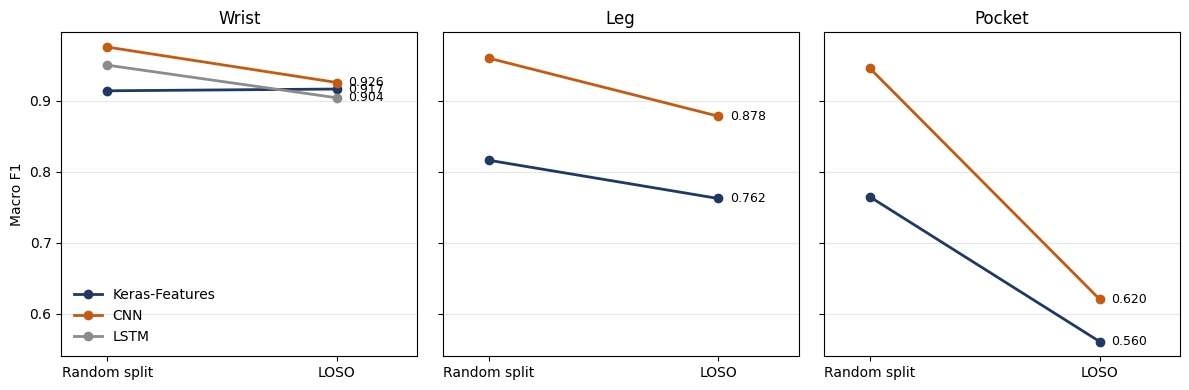

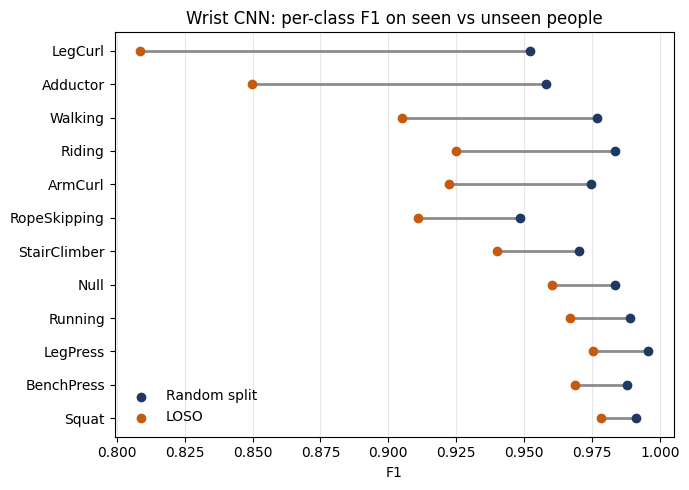

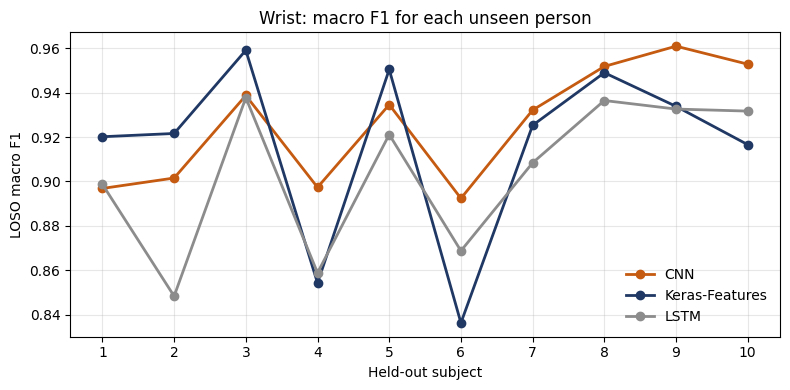

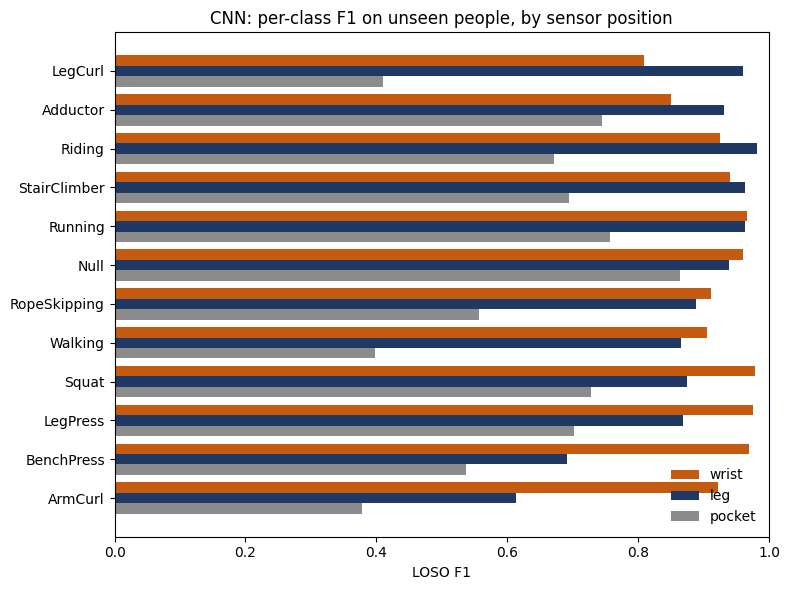

Figures saved to /content/paiml2/figures_final


In [ ]:
var_orange_txt = "#C55A11"
var_blue_txt = "#1F3864"
var_grey_txt = "#8C8C8C"
var_modelcolours_dict = {"CNN": var_orange_txt, "Keras-Features": var_blue_txt, "LSTM": var_grey_txt}
var_poscolours_dict = {"wrist": var_orange_txt, "leg": var_blue_txt, "pocket": var_grey_txt}


def save_figure(var_fig_obj, var_name_txt):
    var_fig_obj.tight_layout()
    var_fig_obj.savefig(f"{var_figuresdir_txt}/{var_name_txt}.png", dpi=200, bbox_inches='tight')
    plt.show()


# Figure 1: random split vs LOSO per model, one panel per position
var_fig_obj, var_axes_arr = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for var_ax_obj, var_position_txt in zip(var_axes_arr, ["wrist", "leg", "pocket"]):
    var_rows_df = var_latest_df[(var_latest_df['position'] == var_position_txt)
                                & (var_latest_df['model'] != "Majority")]
    for _, var_row_ser in var_rows_df.iterrows():
        var_scores_list = [var_row_ser['random_macro_f1'], var_row_ser['loso_macro_f1_mean']]
        var_ax_obj.plot([0, 1], var_scores_list, marker='o', lw=2,
                        color=var_modelcolours_dict[var_row_ser['model']], label=var_row_ser['model'])
        var_ax_obj.text(1.05, var_scores_list[1], f"{var_scores_list[1]:.3f}", va='center', fontsize=9)
    var_ax_obj.set_xticks([0, 1], ["Random split", "LOSO"])
    var_ax_obj.set_xlim(-0.2, 1.35)
    var_ax_obj.set_title(var_position_txt.capitalize())
    var_ax_obj.grid(axis='y', alpha=0.3)
var_axes_arr[0].set_ylabel("Macro F1")
var_axes_arr[0].legend(frameon=False)
save_figure(var_fig_obj, "fig1_protocol_slope")


# Figure 2: wrist CNN per-class F1, random vs LOSO
var_fig_obj, var_ax_obj = plt.subplots(figsize=(7, 5))
var_plot_df = var_perclass_df.sort_values('drop')
var_ypos_arr = np.arange(len(var_plot_df))
var_ax_obj.hlines(var_ypos_arr, var_plot_df['f1_loso'], var_plot_df['f1_random'], color=var_grey_txt, lw=2)
var_ax_obj.scatter(var_plot_df['f1_random'], var_ypos_arr, color=var_blue_txt, zorder=3, label="Random split")
var_ax_obj.scatter(var_plot_df['f1_loso'], var_ypos_arr, color=var_orange_txt, zorder=3, label="LOSO")
var_ax_obj.set_yticks(var_ypos_arr, var_plot_df['exercise'])
var_ax_obj.set_xlabel("F1")
var_ax_obj.set_title("Wrist CNN: per-class F1 on seen vs unseen people")
var_ax_obj.grid(axis='x', alpha=0.3)
var_ax_obj.legend(frameon=False, loc='lower left')
save_figure(var_fig_obj, "fig2_perclass_drop")


# Figure 3: wrist per-subject LOSO macro F1
var_fig_obj, var_ax_obj = plt.subplots(figsize=(8, 4))
for var_modelname_txt in ["CNN", "Keras-Features", "LSTM"]:
    var_ax_obj.plot(var_subject_df.index, var_subject_df[var_modelname_txt], marker='o', lw=2,
                    color=var_modelcolours_dict[var_modelname_txt], label=var_modelname_txt)
var_ax_obj.set_xticks(var_subject_df.index)
var_ax_obj.set_xlabel("Held-out subject")
var_ax_obj.set_ylabel("LOSO macro F1")
var_ax_obj.set_title("Wrist: macro F1 for each unseen person")
var_ax_obj.grid(alpha=0.3)
var_ax_obj.legend(frameon=False)
save_figure(var_fig_obj, "fig3_per_subject")


# Figure 4: CNN per-class LOSO F1 by sensor position
var_fig_obj, var_ax_obj = plt.subplots(figsize=(8, 6))
var_plot_df = var_position_df.iloc[::-1]
var_ypos_arr = np.arange(len(var_plot_df))
var_height_float = 0.27
for i, var_position_txt in enumerate(["wrist", "leg", "pocket"]):
    var_ax_obj.barh(var_ypos_arr + (1 - i) * var_height_float, var_plot_df[var_position_txt],
                    height=var_height_float, color=var_poscolours_dict[var_position_txt], label=var_position_txt)
var_ax_obj.set_yticks(var_ypos_arr, var_plot_df.index)
var_ax_obj.set_xlabel("LOSO F1")
var_ax_obj.set_xlim(0, 1)
var_ax_obj.set_title("CNN: per-class F1 on unseen people, by sensor position")
var_ax_obj.legend(frameon=False, loc='lower right')
save_figure(var_fig_obj, "fig4_position_perclass")

print("Figures saved to", var_figuresdir_txt)

## 11. Download results
Zips the results log, result files and figures. Needed when not using Drive, as session storage is wiped.

In [ ]:
import zipfile

var_zippath_txt = "/content/paiml2_results.zip"
with zipfile.ZipFile(var_zippath_txt, "w") as var_zip_obj:
    for var_folder_txt in [var_resultsdir_txt, var_figuresdir_txt]:  # cache left out, too big
        for var_name_txt in os.listdir(var_folder_txt):
            var_path_txt = os.path.join(var_folder_txt, var_name_txt)
            var_zip_obj.write(var_path_txt, os.path.relpath(var_path_txt, var_basedir_txt))

files.download(var_zippath_txt)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>